# Fixed-schedule regridding with automatic differentiation

This notebook is a minimal test of one planned regrid while retaining JAX automatic differentiation for `dL/dA`. It evolves from the linear grid to `T_REGRID`, transfers the state to a fixed Sinh grid, then continues to `T_FINAL` and differentiates the total scalar-field path length `L` with respect to the initial amplitude.

The regrid time and destination grid are fixed during this test. The adaptive regrid trigger and the multi-amplitude gradient-descent search are later steps; they are intentionally not included here.

## Imports

In [4]:
import sys
sys.path.append("../source")

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import diffrax as dfx

from core.spacing import LinearSpacing, SinhSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import (
    idx_phi,
    idx_lapse,
    idx_hrr,
    idx_htt,
    idx_hpp,
)


## Grid and run settings

In [20]:
# Fixed setup for the first regridding + AD test.
A = 0.22
r0 = 0.0
sigma = 1.0
num_points = 401
r_max = 10.0
T = 7.5
t_regrid = 6.0
dt0 = 0.0025
RECOVERY_WINDOW_TIME = 0.5
RECOVERY_MIN_RISE = 0.05
RECOVERY_MAX_LATE_DROP = 0.03
SUBCRITICAL_FINAL_LAPSE = 0.9

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)
spacing = LinearSpacing(
    num_points=num_points,
    r_max=r_max,
    extent=SpacingExtent.HALF,
)
grid = Grid(spacing, state_vector)
background = FlatSphericalBackground(grid.r)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
r_physical = grid.r[physical]
dr = grid.derivs.dx


## Initial data

In [21]:
def scalar_profile(r, amplitude, sigma):
    return amplitude * r**2 * jnp.exp(-(r / sigma)**2)

scalar_profile_dr = jax.grad(scalar_profile, argnums=0)

def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
    scalar_profile_dr,
    in_axes=(0, None, None),)(r_aux, amplitude, sigma)

    source = jnp.pi * du_dr**2
    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )
    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr, amplitude, r0, sigma
    )
    u_physical = scalar_profile(
        r_physical, amplitude, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(psi_physical**-2)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)


## State transfer between grids

In [22]:
def interpolate_to_new_grid(state, x_old, x_new, num_ghosts=NUM_GHOSTS):
    """Seven-point Lagrange interpolation, following David's regrid helper."""
    stencil_size = 2 * num_ghosts + 1
    n_old = x_old.shape[0]
    n_new = x_new.shape[0]
    num_vars = state.shape[0]

    raw_indices = jnp.searchsorted(x_old, x_new)
    start_indices = jnp.clip(
        raw_indices - stencil_size // 2,
        0,
        n_old - stencil_size,
    )

    def interpolate_one_point(x_target, start_index):
        x_stencil = jax.lax.dynamic_slice(
            x_old, (start_index,), (stencil_size,)
        )
        differences = x_target - x_stencil
        pair_differences = x_stencil[:, None] - x_stencil[None, :]

        diagonal = jnp.eye(stencil_size, dtype=bool)
        numerators = jnp.prod(
            jnp.where(diagonal, 1.0, differences[None, :]),
            axis=1,
        )
        denominators = jnp.prod(
            jnp.where(diagonal, 1.0, pair_differences),
            axis=1,
        )
        weights = numerators / denominators

        def interpolate_one_variable(variable_values):
            values = jax.lax.dynamic_slice(
                variable_values, (start_index,), (stencil_size,)
            )
            return jnp.dot(weights, values)

        return jax.vmap(interpolate_one_variable)(state)

    interior_slice = slice(num_ghosts, n_new - num_ghosts)
    interpolated_interior = jax.vmap(interpolate_one_point)(
        x_new[interior_slice],
        start_indices[interior_slice],
    ).T

    new_state = jnp.zeros((num_vars, n_new), dtype=state.dtype)
    return new_state.at[:, interior_slice].set(interpolated_interior)


def enforce_det_constraint(state):
    h_pp = 1.0 / ((1.0 + state[idx_hrr]) * (1.0 + state[idx_htt])) - 1.0
    return state.at[idx_hpp].set(h_pp)


## Evolution segment solver

In [23]:
def solve_regrid_test_segment(y0, t_start, t_end, test_grid, test_background, dt_segment):
    def rhs(t, state, args):
        return get_rhs(t, state, test_grid, test_background, matter)

    def collapse_condition(t, state, args, **kwargs):
        state_grid = state.reshape(test_grid.NUM_VARS, test_grid.N)
        return state_grid[idx_lapse, NUM_GHOSTS] <= 5e-3

    def save_central_scalar(t, state, args):
        state_grid = state.reshape(test_grid.NUM_VARS, test_grid.N)
        return state_grid[matter.idx_u, NUM_GHOSTS]

    def save_central_lapse(t, state, args):
        state_grid = state.reshape(test_grid.NUM_VARS, test_grid.N)
        return state_grid[idx_lapse, NUM_GHOSTS]

    saveat = dfx.SaveAt(subs=[
        dfx.SubSaveAt(t1=True),
        dfx.SubSaveAt(t0=True, steps=True, fn=save_central_scalar),
        dfx.SubSaveAt(t0=True, steps=True, fn=save_central_lapse),
    ])

    max_steps = max(2000,int(np.ceil((t_end - t_start) / dt_segment)) + 10,)

    return dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs),
        solver=dfx.Dopri5(),
        t0=t_start,
        t1=t_end,
        dt0=dt_segment,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=saveat,
        adjoint=dfx.ForwardMode(),
        event=dfx.Event(collapse_condition),
        max_steps=max_steps,
    )


## Run the fixed-schedule AD test

In [61]:
# Build the destination grid once, outside the differentiated function.
# This keeps the grid size and regrid schedule fixed during jax.jvp.
ad_test_min_dr = float(spacing.min_dr) / 2.0
ad_test_grid_params = SinhSpacing.get_parameters(
    r_max=r_max,
    min_dr=ad_test_min_dr,
    max_dr=float(spacing.min_dr),
    extent=SpacingExtent.HALF,
)
ad_test_grid_params["num_points"] = (
    (ad_test_grid_params["num_points"] + 63) // 64
) * 64
ad_test_spacing = SinhSpacing(**ad_test_grid_params)
ad_test_grid = Grid(ad_test_spacing, state_vector)
ad_test_background = FlatSphericalBackground(ad_test_grid.r)
ad_test_dt = dt0 * float(ad_test_spacing.min_dr) / float(spacing.min_dr)

# Keep these choices fixed while differentiating.
ad_test_A = 0.22
ad_test_t_regrid = 6.0
ad_test_t_final = T


def _series_variation_and_endpoints(times, values):
    valid = jnp.isfinite(times) & jnp.isfinite(values)
    clean_values = jnp.where(valid, values, 0.0)
    valid_pairs = valid[:-1] & valid[1:]
    variation = jnp.sum(
        jnp.where(valid_pairs, jnp.abs(jnp.diff(clean_values)), 0.0)
    )

    indices = jnp.arange(values.shape[0])
    first_index = jnp.argmax(valid.astype(jnp.int32))
    last_index = jnp.max(jnp.where(valid, indices, 0))
    first_value = values[first_index]
    last_value = values[last_index]
    has_finite_sample = jnp.any(valid)
    no_nonfinite_value_at_finite_time = ~jnp.any(
        jnp.isfinite(times) & ~jnp.isfinite(values)
    )
    return (
        variation,
        first_value,
        last_value,
        has_finite_sample & no_nonfinite_value_at_finite_time,
    )


def fixed_schedule_regrid_metrics(amplitude, regrid_time=ad_test_t_regrid):
    # Segment 1: evolve on the original linear grid to the scheduled regrid.
    initial_state = make_initial_state(amplitude)
    before = solve_regrid_test_segment(
        initial_state,
        0.0,
        regrid_time,
        grid,
        background,
        dt0,
    )

    state_at_regrid = before.ys[0]
    if state_at_regrid.ndim == 2:
        state_at_regrid = state_at_regrid[-1]
    state_at_regrid = state_at_regrid.reshape(grid.NUM_VARS, grid.N)

    # Linear x is the source coordinate; map destination radii into it.
    x_targets = spacing.x_of_r(ad_test_grid.r)
    transferred = interpolate_to_new_grid(
        state_at_regrid,
        spacing.x,
        x_targets,
    )
    transferred = enforce_det_constraint(transferred)
    transferred = ad_test_grid.fill_boundaries(transferred)

    # Segment 2: continue on the fixed Sinh grid.
    after = solve_regrid_test_segment(
        transferred.reshape(-1),
        regrid_time,
        ad_test_t_final,
        ad_test_grid,
        ad_test_background,
        ad_test_dt,
    )

    before_variation, _, before_last, before_finite = (
        _series_variation_and_endpoints(before.ts[1], before.ys[1])
    )
    after_variation, after_first, _, after_finite = (
        _series_variation_and_endpoints(after.ts[1], after.ys[1])
    )

    # Include the scalar change across the transfer in the total path length.
    regrid_jump = jnp.abs(after_first - before_last)
    total_L = before_variation + regrid_jump + after_variation

    final_state = after.ys[0]
    if final_state.ndim == 2:
        final_state = final_state[-1]
    final_state_grid = final_state.reshape(
        ad_test_grid.NUM_VARS, ad_test_grid.N
    )
       
    
    final_state_finite = jnp.all(jnp.isfinite(final_state))
    final_lapse = final_state_grid[idx_lapse, NUM_GHOSTS]
    collapse_event = jnp.asarray(
        after.result == dfx.RESULTS.event_occurred
    )

    diagnostics = (
        before_finite,
        after_finite,
        final_state_finite,
        jnp.isfinite(total_L),
        final_lapse,
        collapse_event,
        before.ts[2],
        before.ys[2],
        after.ts[2],
        after.ys[2],
        before.ts[1],
        before.ys[1],
        after.ts[1],
        after.ys[1],
    )
    return total_L, diagnostics


# ad_test_L_and_diagnostics, ad_test_dL_dA, ad_test_diagnostics = jax.jvp(
#     fixed_schedule_regrid_metrics,
#     (jnp.asarray(ad_test_A, dtype=jnp.float64),),
#     (jnp.asarray(1.0, dtype=jnp.float64),),
#     has_aux=True,
# )

# print(f"Test amplitude A: {ad_test_A:.8f}")
# print(f"Fixed regrid time: t = {ad_test_t_regrid:.3f}")
# print(f"Grid points after regrid: {ad_test_grid.N}")
# print(f"L across both segments: {float(ad_test_L_and_diagnostics):.8g}")
# print(f"AD derivative dL/dA: {float(ad_test_dL_dA):.8g}")
# print("Finite data flags (before, after, final state, L):",
#       tuple(bool(x) for x in ad_test_diagnostics))
# print("Finite AD derivative:", bool(jnp.isfinite(ad_test_dL_dA)))


In [ ]:
# print(
#     "Finite data flags (before, after, final state, L):",
#     tuple(bool(x) for x in ad_test_diagnostics[:4]),
# )
# print("Final central lapse:", float(ad_test_diagnostics[4]))
# print("Collapse event:", bool(ad_test_diagnostics[5]))
# print(
#     "Lapse samples before/after regrid:",
#     len(ad_test_diagnostics[7]),
#     len(ad_test_diagnostics[9]),
#)

Finite data flags (before, after, final state, L): (True, True, True, True)
Final central lapse: 0.9483823711619899
Collapse event: False
Lapse samples before/after regrid: 2411 2001


In [60]:
REGRID_CURVATURE_THRESHOLD = 15.0
REGRID_LAPSE_WARNING = 0.1
REGRID_CHECK_INTERVAL = 0.05


def _state_requests_regrid(state, current_grid):
    state = state.reshape(current_grid.NUM_VARS, current_grid.N)

    if not bool(jnp.all(jnp.isfinite(state))):
        return False, "nonfinite state"

    dx = current_grid.derivs.dx
    interior = slice(NUM_GHOSTS + 1, -NUM_GHOSTS - 1)
    triggered = []

    for variable_index, label in (
        (matter.idx_u, "scalar curvature"),
        (idx_lapse, "lapse curvature"),
    ):
        second_derivative = (
            current_grid.derivs.dxn_matrix[2] @ state[variable_index]
        ) / (dx * dx)

        curvature_scale = 1.0 / jnp.sqrt(
            jnp.maximum(jnp.abs(second_derivative[interior]), 1e-30)
        )
        min_curvature_scale = float(jnp.min(curvature_scale))

        if min_curvature_scale < REGRID_CURVATURE_THRESHOLD * float(dx):
            triggered.append(label)

    central_lapse = float(state[idx_lapse, NUM_GHOSTS])
    if central_lapse < REGRID_LAPSE_WARNING:
        triggered.append(f"central lapse {central_lapse:.4g}")

    return bool(triggered), ", ".join(triggered)


def discover_regrid_schedule(amplitude):
    """Probe without AD and choose zero or one regrid time."""
    n_checks = int(np.ceil(T / REGRID_CHECK_INTERVAL)) + 1
    check_times = jnp.linspace(0.0, T, n_checks)

    def rhs(t, state, args):
        return get_rhs(t, state, grid, background, matter)

    def collapse_condition(t, state, args, **kwargs):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        return state_grid[idx_lapse, NUM_GHOSTS] <= 5e-3

    probe = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs),
        solver=dfx.Dopri5(),
        t0=0.0,
        t1=T,
        dt0=dt0,
        y0=make_initial_state(amplitude),
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=dfx.SaveAt(ts=check_times),
        adjoint=dfx.ForwardMode(),
        event=dfx.Event(collapse_condition),
        max_steps=max(2000, int(np.ceil(T / dt0)) + 10),
    )

    times = np.asarray(probe.ts)
    states = np.asarray(probe.ys)

    if states.ndim == 1:
        states = states[None, :]

    for time, flat_state in zip(times, states):
        if not np.isfinite(time):
            continue

        if not np.isfinite(flat_state).all():
            return {
                "status": "failed",
                "time": float(time),
                "reason": "nonfinite probe state",
            }

        should_regrid, reason = _state_requests_regrid(flat_state, grid)
        if should_regrid:
            return {
                "status": "regrid",
                "time": float(time),
                "reason": reason,
            }

    if probe.result == dfx.RESULTS.event_occurred:
        return {
            "status": "collapse",
            "time": float(times[np.isfinite(times)][-1]),
            "reason": "collapse event before a regrid trigger",
        }

    if probe.result != dfx.RESULTS.successful:
        return {
            "status": "failed",
            "time": None,
            "reason": str(probe.result),
        }

    return {
        "status": "no_regrid",
        "time": None,
        "reason": "no trigger before T",
    }


def fixed_linear_metrics(amplitude):
    """Calculate L without regridding if the probe found no trigger."""
    solution = solve_regrid_test_segment(
        make_initial_state(amplitude),
        0.0,
        T,
        grid,
        background,
        dt0,
    )

    variation, _, _, history_finite = _series_variation_and_endpoints(
        solution.ts[1],
        solution.ys[1],
    )

    final_state = solution.ys[0]
    if final_state.ndim == 2:
        final_state = final_state[-1]

    final_state_grid = final_state.reshape(grid.NUM_VARS, grid.N)
    collapse_event = jnp.asarray(
        solution.result == dfx.RESULTS.event_occurred
    )
    final_lapse = final_state_grid[idx_lapse, NUM_GHOSTS]

    diagnostics = (
        history_finite,
        jnp.all(jnp.isfinite(final_state)),
        jnp.isfinite(variation),
        final_lapse,
        collapse_event,
        solution.ts[2],
        solution.ys[2],
        solution.ts[1],
        solution.ys[1],
    )
    return variation, diagnostics

def _finite_lapse_lists(times, lapse):
    times = np.asarray(times)
    lapse = np.asarray(lapse)
    valid = np.isfinite(times) & np.isfinite(lapse)
    return times[valid].tolist(), lapse[valid].tolist()

def lapse_recovery_test(lapse_times, lapse_history):
    times = np.asarray(lapse_times, dtype=float)
    lapse = np.asarray(lapse_history, dtype=float)

    valid = np.isfinite(times) & np.isfinite(lapse)
    times = times[valid]
    lapse = lapse[valid]

    if len(lapse) < 3:
        return False, 0.0, 0.0

    minimum_index = int(np.argmin(lapse))
    final_lapse = float(lapse[-1])
    minimum_lapse = float(lapse[minimum_index])
    recovery_rise = final_lapse - minimum_lapse

    window_start = float(times[-1]) - RECOVERY_WINDOW_TIME
    window_indices = np.flatnonzero(times >= window_start)

    if len(window_indices) < 3:
        return False, recovery_rise, 0.0

    # The minimum must come before the final recovery window.
    if minimum_index >= window_indices[0]:
        return False, recovery_rise, 0.0

    late_peak = float(np.max(lapse[window_indices]))
    late_drop = late_peak - final_lapse

    recovering = (
        recovery_rise >= RECOVERY_MIN_RISE
        and late_drop <= RECOVERY_MAX_LATE_DROP
    )

    changes = np.diff(lapse[window_indices])
    up_fraction = float(np.mean(changes > 0.0))

    return bool(recovering), recovery_rise, up_fraction

PERSISTENT_LOW_LAPSE_THRESHOLD = 0.02
PERSISTENT_LOW_LAPSE_TIME = 0.5


def lapse_stays_low(lapse_times, lapse_history):
    times = np.asarray(lapse_times, dtype=float)
    lapse = np.asarray(lapse_history, dtype=float)

    valid = np.isfinite(times) & np.isfinite(lapse)
    times = times[valid]
    lapse = lapse[valid]

    if len(lapse) < 3:
        return False

    in_final_window = times >= times[-1] - PERSISTENT_LOW_LAPSE_TIME
    tail_lapse = lapse[in_final_window]

    if len(tail_lapse) < 3:
        return False

    fraction_low = np.mean(
        tail_lapse <= PERSISTENT_LOW_LAPSE_THRESHOLD
    )

    return (
        lapse[-1] <= PERSISTENT_LOW_LAPSE_THRESHOLD
        and fraction_low >= 0.95
    )


def two_pass_regrid_ad(amplitude):
    """Discover a regrid schedule, then calculate L and dL/dA with it fixed."""
    schedule = discover_regrid_schedule(amplitude)

    # If the probe fails before it can produce a metric, record the outcome.
    if schedule["status"] == "failed":
        print("Probe failed:", schedule["reason"])
        return {
            "A": float(amplitude),
            "schedule": schedule,
            "outcome": "failed",
            "L": float("nan"),
            "J": float("nan"),
            "dL_dA": float("nan"),
            "dJ_dA": float("nan"),
            "final_lapse": float("nan"),
            "finite_checks": (),
            "lapse_times": [],
            "lapse_history": [],
        }

    if schedule["status"] == "collapse":
        print("Collapse occurred before the regrid trigger.")
        return {
            "A": float(amplitude),
            "schedule": schedule,
            "outcome": "super",
            "L": float("nan"),
            "J": float("nan"),
            "dL_dA": float("nan"),
            "dJ_dA": float("nan"),
            "final_lapse": float("nan"),
            "finite_checks": (),
            "lapse_times": [],
            "lapse_history": [],
        }

    # Choose the metric function using the schedule found by the probe.
    if schedule["status"] == "regrid":
        selected_time = schedule["time"]

        def metrics_for_ad(a):
            return fixed_schedule_regrid_metrics(a, selected_time)

    else:
        def metrics_for_ad(a):
            return fixed_linear_metrics(a)

    # Differentiate L with respect to amplitude. The schedule stays fixed
    # during this AD calculation.
    L_value, dL_dA, diagnostics = jax.jvp(
        metrics_for_ad,
        (jnp.asarray(amplitude, dtype=jnp.float64),),
        (jnp.asarray(1.0, dtype=jnp.float64),),
        has_aux=True,
    )

    # Extract finite checks, final lapse, and lapse history.
    if schedule["status"] == "regrid":
        finite_checks = tuple(bool(x) for x in diagnostics[:4])
        final_lapse = float(diagnostics[4])
        collapse_event = bool(diagnostics[5])

        times_before, lapse_before = _finite_lapse_lists(
            diagnostics[6], diagnostics[7]
        )
        times_after, lapse_after = _finite_lapse_lists(
            diagnostics[8], diagnostics[9]
        )

        # Keep both samples at the regrid time to show any transfer jump.
        lapse_times = times_before + times_after
        lapse_history = lapse_before + lapse_after

        scalar_times_before, scalar_before = _finite_lapse_lists(
            diagnostics[10], diagnostics[11]
        )
        scalar_times_after, scalar_after = _finite_lapse_lists(
            diagnostics[12], diagnostics[13]
        )
        scalar_times = scalar_times_before + scalar_times_after
        scalar_history = scalar_before + scalar_after

    else:
        finite_checks = tuple(bool(x) for x in diagnostics[:3])
        final_lapse = float(diagnostics[3])
        collapse_event = bool(diagnostics[4])
        lapse_times, lapse_history = _finite_lapse_lists(
            diagnostics[5], diagnostics[6]
        )

        scalar_times, scalar_history = _finite_lapse_lists(
        diagnostics[7], diagnostics[8]
    )

    L_value = float(L_value)
    dL_dA = float(dL_dA)


    recovering, recovery_rise, recovery_up_fraction = lapse_recovery_test(
        lapse_times, lapse_history
    )

    if (
        not all(finite_checks)
        or not np.isfinite(L_value)  # use total_L here if that's your variable name
        or not np.isfinite(final_lapse)
    ):
        outcome = "failed"
    elif collapse_event:
        outcome = "super"
    elif final_lapse > SUBCRITICAL_FINAL_LAPSE:
        outcome = "sub"
    elif lapse_stays_low(lapse_times, lapse_history):
        outcome = "super"
    elif recovering:
        outcome = "sub"
    else:
        outcome = "unresolved"

    J = float(np.exp(-2.0 * L_value)) if np.isfinite(L_value) else float("nan")

    if np.isfinite(J) and np.isfinite(dL_dA):
        dJ_dA = -2.0 * J * dL_dA
    else:
        dJ_dA = float("nan")

    return {
        "A": float(amplitude),
        "schedule": schedule,
        "outcome": outcome,
        "L": L_value,
        "J": J,
        "dL_dA": dL_dA,
        "dJ_dA": dJ_dA,
        "final_lapse": final_lapse,
        "finite_checks": finite_checks,
        "collapse_event": collapse_event,
        "recovery_rise": recovery_rise,
        "recovery_up_fraction": recovery_up_fraction,
        "lapse_times": lapse_times,
        "lapse_history": lapse_history,
        "scalar_times": scalar_times,
        "scalar_history": scalar_history,
    }

In [39]:
def get_amplitude_bracket(records):
    # Include unresolved runs on the subcritical side only if that is still
    # your chosen policy for proposing amplitudes.
    sub_values = [
        float(r["A"]) for r in records
        if r.get("outcome") in ("sub", "unresolved")
    ]
    super_values = [
        float(r["A"]) for r in records
        if r.get("outcome") == "super"
    ]

    if not sub_values or not super_values:
        return None

    lower = max(sub_values)
    upper = min(super_values)

    if lower >= upper:
        raise ValueError(f"Invalid amplitude bracket: {lower} >= {upper}")

    return lower, upper

In [40]:
def print_run_stats(record, label):
    print(
        f"{label}: A={record['A']:.8f}, "
        f"outcome={record['outcome']}, "
        f"L={record.get('L', float('nan')):.6g}, "
        f"J={record.get('J', float('nan')):.6g}, "
        f"dJ/dA={record.get('dJ_dA', float('nan')):.6g}, "
        f"final lapse={record.get('final_lapse', float('nan')):.6g}",
        flush=True,
    )
    print("Schedule:", record.get("schedule"), flush=True)

In [59]:
def five_regridded_gradient_runs(
    A_start=0.36285883,
    max_runs=5,
    initial_step_size=0.01,
    max_amplitude_step=0.02,
    max_backtracks=8,
    history=None,
    step_size=None,
):
    if history is None:
        history = []
    else:
        history = list(history)  # copy the saved records

    if history:
        accepted_records = [
            run for run in history if run.get("accepted", False)
        ]
        if not accepted_records:
            raise ValueError("History contains no accepted run to continue from.")

        current = accepted_records[-1]
        evaluations = len(history)
        print_run_stats(current, "Continuing from accepted run")

        if step_size is None:
            step_size = initial_step_size
    else:
        current = two_pass_regrid_ad(A_start)
        current["accepted"] = (
            current["outcome"] in ("sub", "unresolved")
            and np.isfinite(current["J"])
        )
        history.append(current)
        evaluations = 1
        print_run_stats(current, "Starting run")

        if not current["accepted"]:
            print("Stopping: the starting amplitude failed or was supercritical.")
            return history

        if step_size is None:
            step_size = initial_step_size

    while evaluations < max_runs:
        gradient = current["dJ_dA"]

        if not np.isfinite(gradient) or abs(gradient) < 1e-12:
            print("Stopping: the objective gradient is invalid or too small.")
            break

        accepted_trial = False
        trial_step_size = step_size

        for _ in range(max_backtracks):
            if evaluations >= max_runs:
                break

            change = float(np.clip(
                -trial_step_size * gradient,
                -max_amplitude_step,
                max_amplitude_step,
            ))
            A_trial = current["A"] + change

            if A_trial <= 0.0 or A_trial == current["A"]:
                trial_step_size *= 0.5
                continue

            # If both sides are known, require the trial to be inside the bracket.
            bracket = get_amplitude_bracket(history)
            if bracket is not None:
                lower, upper = bracket
                if not lower < A_trial < upper:
                    print(
                        f"A={A_trial:.8f} is outside the bracket "
                        f"({lower:.8f}, {upper:.8f}); halving step.",
                        flush=True,
                    )
                    trial_step_size *= 0.5
                    continue
            print(
                f"\nRunning evaluation {evaluations + 1}/{max_runs} "
                f"at A={A_trial:.8f} ...",
                flush=True,
            )                   
            
            trial = two_pass_regrid_ad(A_trial)
            trial["accepted"] = False
            history.append(trial)
            evaluations += 1

            print_run_stats(trial, f"Evaluation {evaluations}")
            acceptable_side = trial["outcome"] in ("sub", "unresolved")
            if (
                acceptable_side
                and np.isfinite(trial["J"])
                and trial["J"] < current["J"]
            ):
                trial["accepted"] = True
                accepted_trial = True
                current = trial
                step_size = min(initial_step_size, 1.25 * trial_step_size)
                print("Trial accepted as the new current run.", flush=True)
                break

            # A rejected supercritical or non-improving trial stays in history.
            # If it was supercritical, the next bracket check uses it as an
            # upper bound. Try a smaller step from the last accepted run.

            print("Trial rejected; reducing the gradient step.", flush=True)
            trial_step_size *= 0.5

        if not accepted_trial:
            print("Stopping: no tested gradient step lowered J.")
            break

    # Report a next proposal only if it is inside the known bracket.

        # Report a next proposal only if it is inside the known bracket.
    next_A_proposed = np.nan
    proposal_step_size = step_size

    for attempt in range(max_backtracks):
        change = float(np.clip(
            -proposal_step_size * current["dJ_dA"],
            -max_amplitude_step,
            max_amplitude_step,
        ))
        candidate = current["A"] + change
        bracket = get_amplitude_bracket(history)

        print(
            f"Proposal {attempt + 1}: A={candidate:.8f}, "
            f"step={proposal_step_size:.3g}, bracket={bracket}",
            flush=True,
        )

        if candidate <= 0.0 or candidate == current["A"]:
            proposal_step_size *= 0.5
            continue

        if bracket is not None:
            lower, upper = bracket
            if not lower < candidate < upper:
                proposal_step_size *= 0.5
                continue

        already_tried = any(
            np.isclose(candidate, run["A"], rtol=0.0, atol=1e-14)
            for run in history
        )
        if already_tried:
            proposal_step_size *= 0.5
            continue

        next_A_proposed = candidate
        break
    current["next_A_proposed"] = next_A_proposed

    print(f"Completed {evaluations} amplitude evaluations.")
    print(
        "Next proposed amplitude:",
        f"{next_A_proposed:.8f}"
        if np.isfinite(next_A_proposed)
        else "no untried in-bracket proposal found",
    )

    return history

In [42]:
T = 9.375
ad_test_t_final = T

regrid_history_bracketed = five_regridded_gradient_runs(
    A_start=0.36285883,
    max_runs=5,
)

Starting run: A=0.36285883, outcome=sub, L=1.46611, J=0.053279, dJ/dA=-3.20827, final lapse=0.834682
Schedule: {'status': 'regrid', 'time': 2.4933510638297873, 'reason': 'central lapse 0.09841'}

Running evaluation 2/5 at A=0.38285883 ...
Evaluation 2: A=0.38285883, outcome=super, L=1.44795, J=0.0552493, dJ/dA=-2.40969, final lapse=0.00483794
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 0.09531'}
Trial rejected; reducing the gradient step.

Running evaluation 3/5 at A=0.37890019 ...
Evaluation 3: A=0.37890019, outcome=super, L=1.3901, J=0.0620261, dJ/dA=-1.33014, final lapse=0.00492558
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 0.09623'}
Trial rejected; reducing the gradient step.

Running evaluation 4/5 at A=0.37087951 ...
Evaluation 4: A=0.37087951, outcome=sub, L=1.93331, J=0.0209292, dJ/dA=-5.63545, final lapse=0.816639
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 

In [47]:
regrid_history_continued = five_regridded_gradient_runs(
    history=regrid_history_bracketed,
    step_size=0.003125,
    max_runs=10,  # five more evaluations; the existing five count toward this
)

Continuing from accepted run: A=0.37087951, outcome=sub, L=1.93331, J=0.0209292, dJ/dA=-5.63545, final lapse=0.816639
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 0.09951'}
A=0.38849030 is outside the bracket (0.37087951, 0.37528221); halving step.
A=0.37968491 is outside the bracket (0.37087951, 0.37528221); halving step.
A=0.37528221 is outside the bracket (0.37087951, 0.37528221); halving step.

Running evaluation 6/10 at A=0.37308086 ...
Evaluation 6: A=0.37308086, outcome=super, L=2.58994, J=0.00562864, dJ/dA=-3.83027, final lapse=0.00496646
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 0.09841'}
Trial rejected; reducing the gradient step.

Running evaluation 7/10 at A=0.37198019 ...
Evaluation 7: A=0.37198019, outcome=sub, L=2.14025, J=0.0138358, dJ/dA=-7.12814, final lapse=0.81254
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 0.09894'}
Trial accepted as the new curr

In [49]:
import inspect
print(inspect.signature(five_regridded_gradient_runs))

(A_start=0.36285883, max_runs=5, initial_step_size=0.01, max_amplitude_step=0.02, max_backtracks=8, history=None, step_size=None)


In [53]:
regrid_history_proposal = five_regridded_gradient_runs(
    history=regrid_history_continued,
    step_size=0.0001526,
    max_runs=10,
    max_backtracks=8,
)

Continuing from accepted run: A=0.37285032, outcome=sub, L=3.50766, J=0.00089802, dJ/dA=-37.0826, final lapse=0.799092
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 0.09852'}
Proposal 1: A=0.37850912, step=0.000153, bracket=(0.3728503197685238, 0.37293873152703855)
Proposal 2: A=0.37567972, step=7.63e-05, bracket=(0.3728503197685238, 0.37293873152703855)
Proposal 3: A=0.37426502, step=3.81e-05, bracket=(0.3728503197685238, 0.37293873152703855)
Proposal 4: A=0.37355767, step=1.91e-05, bracket=(0.3728503197685238, 0.37293873152703855)
Proposal 5: A=0.37320399, step=9.54e-06, bracket=(0.3728503197685238, 0.37293873152703855)
Proposal 6: A=0.37302716, step=4.77e-06, bracket=(0.3728503197685238, 0.37293873152703855)
Proposal 7: A=0.37293874, step=2.38e-06, bracket=(0.3728503197685238, 0.37293873152703855)
Proposal 8: A=0.37289453, step=1.19e-06, bracket=(0.3728503197685238, 0.37293873152703855)
Completed 10 amplitude evaluations.
Next proposed amplitude

In [62]:
regrid_history_more = five_regridded_gradient_runs(
    history=regrid_history_proposal,
    step_size=0.0001526,
    max_runs=15,
    max_backtracks=8,
)

Continuing from accepted run: A=0.37285032, outcome=sub, L=3.50766, J=0.00089802, dJ/dA=-37.0826, final lapse=0.799092
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 0.09852'}
A=0.37850912 is outside the bracket (0.37285032, 0.37293873); halving step.
A=0.37567972 is outside the bracket (0.37285032, 0.37293873); halving step.
A=0.37426502 is outside the bracket (0.37285032, 0.37293873); halving step.
A=0.37355767 is outside the bracket (0.37285032, 0.37293873); halving step.
A=0.37320399 is outside the bracket (0.37285032, 0.37293873); halving step.
A=0.37302716 is outside the bracket (0.37285032, 0.37293873); halving step.
A=0.37293874 is outside the bracket (0.37285032, 0.37293873); halving step.

Running evaluation 11/15 at A=0.37289453 ...
Evaluation 11: A=0.37289453, outcome=failed, L=7.21092, J=5.45348e-07, dJ/dA=-0.232223, final lapse=nan
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 0.0985'}
Trial reject

In [63]:
failed_run = next(
    run for run in reversed(regrid_history_more)
    if np.isclose(run["A"], 0.37289453)
)

print("Finite checks:", failed_run.get("finite_checks"))
print("Schedule:", failed_run.get("schedule"))
print("Last saved lapse time:", failed_run["lapse_times"][-1]
      if failed_run.get("lapse_times") else "no finite lapse samples")
print("Last saved lapse:", failed_run["lapse_history"][-1]
      if failed_run.get("lapse_history") else "no finite lapse samples")

Finite checks: (True, False, False, True)
Schedule: {'status': 'regrid', 'time': 2.4434840425531914, 'reason': 'central lapse 0.0985'}
Last saved lapse time: 7.53261041857211
Last saved lapse: 1.0849954820195808


In [64]:
print("Last scalar sample:",
      failed_run["scalar_times"][-1],
      failed_run["scalar_history"][-1])

Last scalar sample: 7.53261041857211 0.005445298273159739


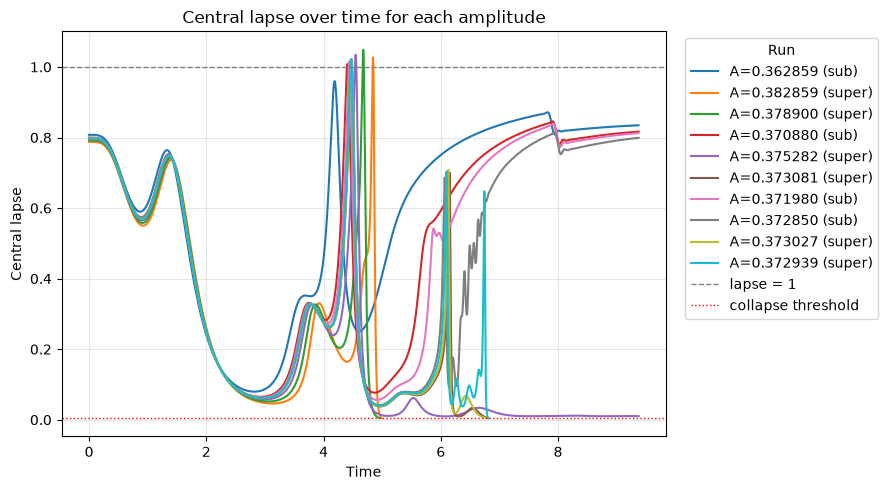

In [54]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

for run in regrid_history_continued:
    if run["lapse_times"]:
        ax.plot(
            run["lapse_times"],
            run["lapse_history"],
            label=f"A={run['A']:.6f} ({run['outcome']})",
        )

ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="lapse = 1")
ax.axhline(5e-3, color="red", linestyle=":", linewidth=1,
           label="collapse threshold")
ax.set_xlabel("Time")
ax.set_ylabel("Central lapse")
ax.set_title("Central lapse over time for each amplitude")
ax.grid(True, alpha=0.3)
ax.legend(title="Run", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

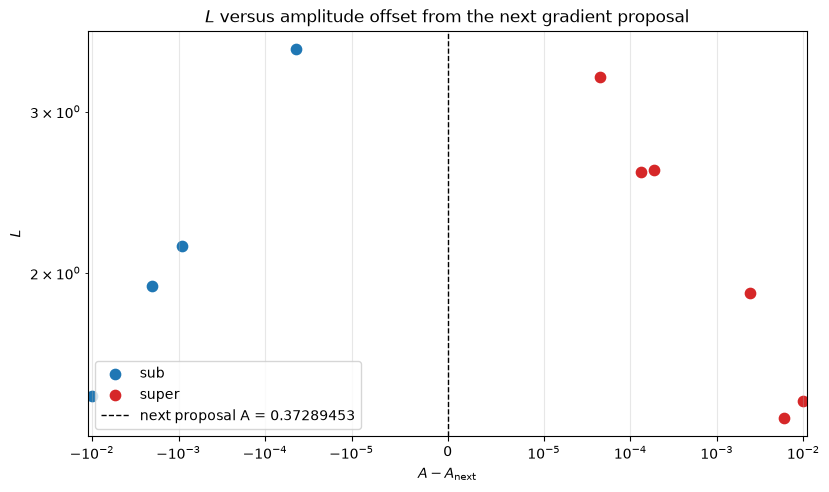

Next proposed amplitude for this plot = 0.37289453


In [57]:
import matplotlib.pyplot as plt
import numpy as np

plot_runs = regrid_history_proposal

# Find the accepted run that has the newly calculated proposal.
proposal_records = [
    run for run in plot_runs
    if run.get("accepted", False)
    and np.isfinite(run.get("next_A_proposed", np.nan))
]

if not proposal_records:
    raise ValueError("No next amplitude proposal was saved in the history.")

A_star_plot = proposal_records[-1]["next_A_proposed"]

fig, ax = plt.subplots(figsize=(8, 5))

colours = {
    "sub": "tab:blue",
    "super": "tab:red",
    "unresolved": "tab:orange",
}

for outcome, colour in colours.items():
    points = [
        run for run in plot_runs
        if run["outcome"] == outcome
        and np.isfinite(run["L"])
    ]

    if points:
        ax.scatter(
            [run["A"] - A_star_plot for run in points],
            [run["L"] for run in points],
            color=colour,
            label=outcome,
            s=55,
        )

ax.axvline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"next proposal A = {A_star_plot:.8f}",
)
ax.set_xlabel(r"$A - A_{\mathrm{next}}$")
ax.set_ylabel(r"$L$")
ax.set_title(r"$L$ versus amplitude offset from the next gradient proposal")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
ax.set_xscale("symlog", linthresh=1e-5)
ax.set_yscale("log")
plt.show()

print(f"Next proposed amplitude for this plot = {A_star_plot:.8f}")

In [11]:
regrid_history = five_regridded_gradient_runs(
    A_start=0.36285883,
    max_runs=5,
)

A=0.36285883, outcome=unresolved, L=1.4637, final lapse=0.858179
Schedule: {'status': 'regrid', 'time': 2.5, 'reason': 'central lapse 0.09764'}
dJ/dA=-3.15678
A=0.38285883, outcome=super, L=1.44795, final lapse=0.00483672
Schedule: {'status': 'regrid', 'time': 2.45, 'reason': 'central lapse 0.09414'}
dJ/dA=-2.50662
A=0.37864272, outcome=super, L=1.38834, final lapse=0.00499422
Schedule: {'status': 'regrid', 'time': 2.45, 'reason': 'central lapse 0.09519'}
dJ/dA=-0.769776
A=0.37075078, outcome=unresolved, L=1.91217, final lapse=0.822652
Schedule: {'status': 'regrid', 'time': 2.45, 'reason': 'central lapse 0.09856'}
dJ/dA=-5.74895
A=0.38871625, outcome=super, L=1.5648, final lapse=0.00498523
Schedule: {'status': 'regrid', 'time': 2.45, 'reason': 'central lapse 0.09348'}
dJ/dA=5.23088
Stopping: no tested gradient step lowered J.
Completed 5 amplitude evaluations.
Next proposed amplitude: 0.38871625


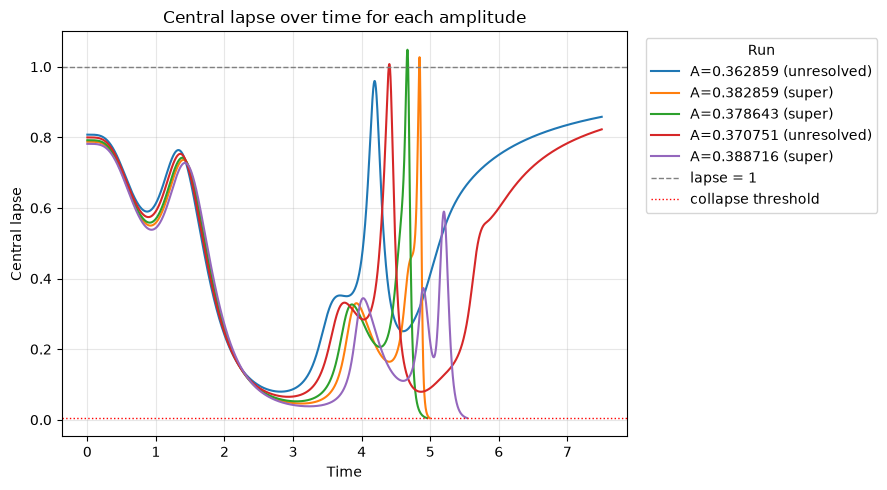

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

for run in regrid_history:
    if run["lapse_times"]:
        ax.plot(
            run["lapse_times"],
            run["lapse_history"],
            label=f"A={run['A']:.6f} ({run['outcome']})",
        )

ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="lapse = 1")
ax.axhline(5e-3, color="red", linestyle=":", linewidth=1,
           label="collapse threshold")
ax.set_xlabel("Time")
ax.set_ylabel("Central lapse")
ax.set_title("Central lapse over time for each amplitude")
ax.grid(True, alpha=0.3)
ax.legend(title="Run", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

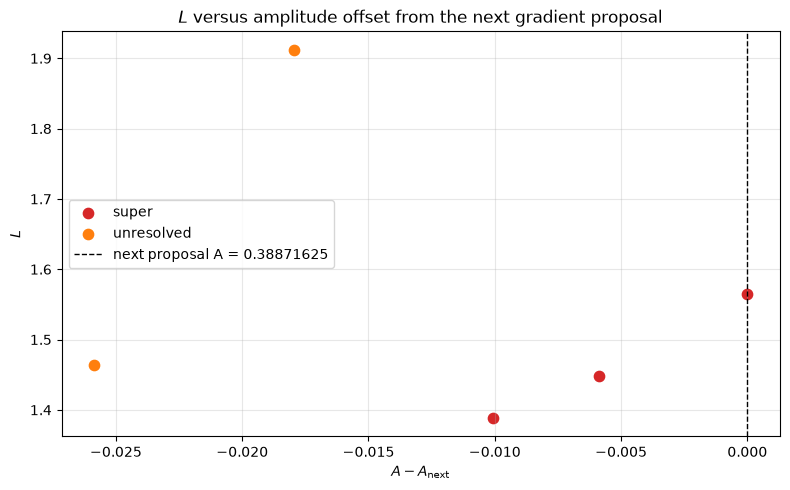

Next proposed amplitude A* for this plot = 0.38871625


In [13]:
import matplotlib.pyplot as plt
import numpy as np

accepted_records = [
    run for run in regrid_history
    if run.get("accepted", False)
]
A_star_plot = accepted_records[-1]["next_A_proposed"]

fig, ax = plt.subplots(figsize=(8, 5))

colours = {
    "sub": "tab:blue",
    "super": "tab:red",
    "unresolved": "tab:orange",
}

for outcome, colour in colours.items():
    points = [
        run for run in regrid_history
        if run["outcome"] == outcome
        and np.isfinite(run["L"])
    ]
    if points:
        ax.scatter(
            [run["A"] - A_star_plot for run in points],
            [run["L"] for run in points],
            color=colour,
            label=outcome,
            s=55,
        )

ax.axvline(0.0, color="black", linestyle="--", linewidth=1,
           label=f"next proposal A = {A_star_plot:.8f}")
ax.set_xlabel(r"$A - A_{\mathrm{next}}$")
ax.set_ylabel(r"$L$")
ax.set_title(r"$L$ versus amplitude offset from the next gradient proposal")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

print(f"Next proposed amplitude A* for this plot = {A_star_plot:.8f}")

In [14]:
T = 9.375
ad_test_t_final = T

regrid_history_extended = five_regridded_gradient_runs(
    A_start=0.36285883,
    max_runs=5,
)

Stopping: no tested gradient step lowered J.
Completed 5 amplitude evaluations.
Next proposed amplitude: 0.38849030


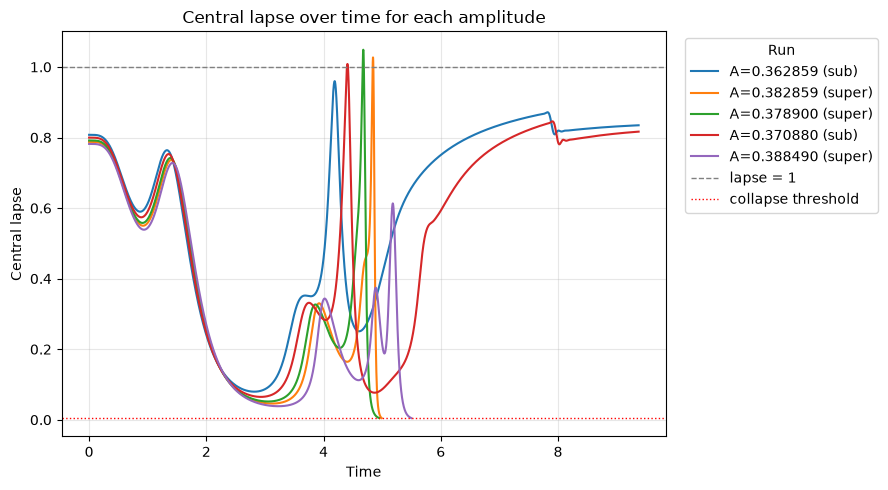

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

for run in regrid_history_extended:
    if run["lapse_times"]:
        ax.plot(
            run["lapse_times"],
            run["lapse_history"],
            label=f"A={run['A']:.6f} ({run['outcome']})",
        )

ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="lapse = 1")
ax.axhline(5e-3, color="red", linestyle=":", linewidth=1,
           label="collapse threshold")
ax.set_xlabel("Time")
ax.set_ylabel("Central lapse")
ax.set_title("Central lapse over time for each amplitude")
ax.grid(True, alpha=0.3)
ax.legend(title="Run", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

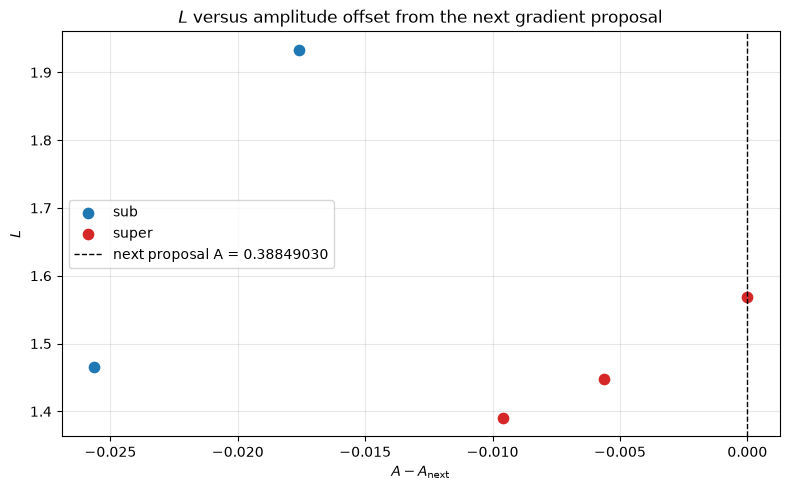

Next proposed amplitude A* for this plot = 0.38849030


In [16]:
import matplotlib.pyplot as plt
import numpy as np

accepted_records = [
    run for run in regrid_history_extended
    if run.get("accepted", False)
]
A_star_plot = accepted_records[-1]["next_A_proposed"]

fig, ax = plt.subplots(figsize=(8, 5))

colours = {
    "sub": "tab:blue",
    "super": "tab:red",
    "unresolved": "tab:orange",
}

for outcome, colour in colours.items():
    points = [
        run for run in regrid_history_extended
        if run["outcome"] == outcome
        and np.isfinite(run["L"])
    ]
    if points:
        ax.scatter(
            [run["A"] - A_star_plot for run in points],
            [run["L"] for run in points],
            color=colour,
            label=outcome,
            s=55,
        )

ax.axvline(0.0, color="black", linestyle="--", linewidth=1,
           label=f"next proposal A = {A_star_plot:.8f}")
ax.set_xlabel(r"$A - A_{\mathrm{next}}$")
ax.set_ylabel(r"$L$")
ax.set_title(r"$L$ versus amplitude offset from the next gradient proposal")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

print(f"Next proposed amplitude A* for this plot = {A_star_plot:.8f}")

In [14]:
ADAPTIVE_TEST_A = 0.37285883
adaptive_test_record = two_pass_regrid_ad(ADAPTIVE_TEST_A)

Amplitude A: 0.37285883
Discovered schedule: {'status': 'regrid', 'time': 2.45, 'reason': 'central lapse 0.09747'}
L: 3.7295373
AD derivative dL/dA: 33392.449
Finite checks: (True, True, True, True)
Finite AD derivative: True


In [8]:
ADAPTIVE_TEST2_A = 0.36285883
adaptive_test_record = two_pass_regrid_ad(ADAPTIVE_TEST2_A)

Amplitude A: 0.36285883
Discovered schedule: {'status': 'regrid', 'time': 2.5, 'reason': 'central lapse 0.09764'}
L: 1.4636986
AD derivative dL/dA: 29.482651
Finite checks: (True, True, True, True)
Finite AD derivative: True


In [15]:
# Check the AD derivative against a central finite difference.
A0 = adaptive_test_record["A"]
t_fixed = adaptive_test_record["schedule"]["time"]
dL_dA_AD = adaptive_test_record["dL_dA"]

eps = 1e-7

L_plus, checks_plus = fixed_schedule_regrid_metrics(
    A0 + eps, regrid_time=t_fixed
)
L_minus, checks_minus = fixed_schedule_regrid_metrics(
    A0 - eps, regrid_time=t_fixed
)

dL_dA_FD = float((L_plus - L_minus) / (2.0 * eps))
relative_difference = abs(dL_dA_FD - dL_dA_AD) / max(
    abs(dL_dA_FD), abs(dL_dA_AD), 1e-12
)

print(f"A = {A0:.8f}, fixed regrid time = {t_fixed:.3f}")
print(f"L(A + eps) = {float(L_plus):.10g}")
print(f"L(A - eps) = {float(L_minus):.10g}")
print(f"AD derivative = {dL_dA_AD:.10g}")
print(f"Finite-difference derivative = {dL_dA_FD:.10g}")
print(f"Relative difference = {relative_difference:.3g}")
print("Finite checks (+eps):", tuple(bool(x) for x in checks_plus))
print("Finite checks (-eps):", tuple(bool(x) for x in checks_minus))

A = 0.37285883, fixed regrid time = 2.450
L(A + eps) = 3.733034237
L(A - eps) = 3.726192222
AD derivative = 33392.44885
Finite-difference derivative = 34210.0774
Relative difference = 0.0239
Finite checks (+eps): (True, True, True, True)
Finite checks (-eps): (True, True, True, True)


In [9]:
# Check the AD derivative against a central finite difference.
A0 = adaptive_test_record["A"]
t_fixed = adaptive_test_record["schedule"]["time"]
dL_dA_AD = adaptive_test_record["dL_dA"]

eps = 1e-7

L_plus, checks_plus = fixed_schedule_regrid_metrics(
    A0 + eps, regrid_time=t_fixed
)
L_minus, checks_minus = fixed_schedule_regrid_metrics(
    A0 - eps, regrid_time=t_fixed
)

dL_dA_FD = float((L_plus - L_minus) / (2.0 * eps))
relative_difference = abs(dL_dA_FD - dL_dA_AD) / max(
    abs(dL_dA_FD), abs(dL_dA_AD), 1e-12
)

print(f"A = {A0:.8f}, fixed regrid time = {t_fixed:.3f}")
print(f"L(A + eps) = {float(L_plus):.10g}")
print(f"L(A - eps) = {float(L_minus):.10g}")
print(f"AD derivative = {dL_dA_AD:.10g}")
print(f"Finite-difference derivative = {dL_dA_FD:.10g}")
print(f"Relative difference = {relative_difference:.3g}")
print("Finite checks (+eps):", tuple(bool(x) for x in checks_plus))
print("Finite checks (-eps):", tuple(bool(x) for x in checks_minus))

A = 0.36285883, fixed regrid time = 2.500
L(A + eps) = 1.463701553
L(A - eps) = 1.463695656
AD derivative = 29.4826513
Finite-difference derivative = 29.48264691
Relative difference = 1.49e-07
Finite checks (+eps): (True, True, True, True)
Finite checks (-eps): (True, True, True, True)


In [10]:
A_control = 0.37285883

L_control, control_checks = fixed_linear_metrics(A_control)

print(f"No-regrid control: A = {A_control:.8f}, T = {T:.3f}")
print(f"L: {float(L_control):.8g}")
print("Finite checks:", tuple(bool(x) for x in control_checks))

No-regrid control: A = 0.37285883, T = 7.500
L: 2.4632861
Finite checks: (True, True, True)


In [11]:
A_compare = 0.37285883
T_compare = 9.375
saved_T = T
saved_ad_test_t_final = ad_test_t_final

try:
    T = T_compare
    ad_test_t_final = T_compare

    L_linear, checks_linear = fixed_linear_metrics(A_compare)
    L_regridded, checks_regridded = fixed_schedule_regrid_metrics(
        A_compare,
        regrid_time=2.45,
    )

    print(f"Comparison at A = {A_compare:.8f}, T = {T_compare:.3f}")
    print(f"No regrid:  L = {float(L_linear):.8g}, "
          f"checks = {tuple(bool(x) for x in checks_linear)}")
    print(f"Regridded:  L = {float(L_regridded):.8g}, "
          f"checks = {tuple(bool(x) for x in checks_regridded)}")
finally:
    T = saved_T
    ad_test_t_final = saved_ad_test_t_final

Comparison at A = 0.37285883, T = 9.375
No regrid:  L = 2.4632861, checks = (True, True, True)
Regridded:  L = 3.7325624, checks = (True, True, True, True)
